# Early Prediction of Poor Air Quality in Indian Cities Using Machine Learning
## A Comparative Analysis of Pollutant and Temporal Factors

**Subject:** Predictive Analysis — College Project
**Dataset:** [Air Quality Data in India (2015–2024)](https://www.kaggle.com/datasets/ankushpanday1/air-quality-data-in-india-2015-2024) (Kaggle)

---

## 1. Project Introduction

**Air pollution** refers to the presence of harmful substances — particulate matter (PM2.5, PM10), gases such as NO2, SO2, CO, O3, and volatile organics like Benzene and Toluene — in the atmosphere at concentrations that can harm human health and the environment. Rapid urbanization, vehicular traffic, industrial activity, and seasonal weather patterns make **urban air quality** a critical public-health and policy concern, particularly in densely populated Indian cities.

The **Air Quality Index (AQI)** is a standardized scale that translates raw pollutant concentrations into a single interpretable number and category (e.g., *Good*, *Moderate*, *Poor*, *Severe*), making it easier for citizens and policymakers to understand health risk at a glance.

**Machine learning (ML)** is useful here because pollution is driven by many interacting factors (multiple pollutants, city-specific characteristics, seasonality, and long-term trends) that are difficult to summarize with simple rules. ML models can learn these relationships from historical data to:

- Estimate AQI from pollutant readings,
- Classify air quality into standardized categories,
- Identify which factors matter most for poor air quality, and
- Support an **early-warning system** that flags high-risk conditions.

This project uses a multi-year (2015–2024), multi-city Indian air-quality dataset to build and compare predictive models for AQI (regression) and AQI category (classification), and to examine city, seasonal, and temporal patterns in pollution. Studying **Indian cities specifically** matters because pollution sources, monitoring infrastructure, seasonal patterns (monsoon, winter inversion, crop-residue burning), and public-health impact differ substantially from other regions, so India-specific models and insights are more actionable for Indian policymakers than global averages.

## 2. Problem Statement

> Air pollution varies across Indian cities and over time due to changes in pollutant concentrations and environmental conditions. Traditional analysis can describe pollution patterns, but predictive analytics can help identify air-quality conditions and determine which factors provide the strongest predictive information. This project applies data preprocessing, exploratory analysis, visualization, and machine-learning techniques to predict AQI/AQI categories and investigate the major factors associated with poor air quality.

**Note:** All relationships discussed in this notebook are *associative/predictive*, not causal. No causal claims are made.

## 3. Project Objectives

1. Predict numerical **AQI** values using available pollutant and temporal information.
2. Predict **AQI categories** (Good / Satisfactory / Moderate / Poor / Very Poor / Severe), if present in the data.
3. Identify the most important variables for predicting AQI.
4. Analyze pollution patterns **across Indian cities**.
5. Analyze pollution patterns **across months, seasons, and years**.
6. Investigate whether using **multiple pollutants** improves predictive performance over PM2.5 alone.
7. Investigate whether **city information** improves prediction.
8. Explore whether **historical observations** can predict future/next-period air quality (if the data supports it).
9. Develop an **early-warning classification** approach for poor/severe air-quality conditions.

## 4. Research Questions

| # | Research Question |
|---|---|
| RQ1 | Can machine learning predict AQI from pollutant concentrations and other available features? |
| RQ2 | Can machine learning predict AQI categories? |
| RQ3 | Which pollutants are the strongest predictors of AQI? |
| RQ4 | Does using multiple pollutants improve prediction compared with using only PM2.5? |
| RQ5 | Does adding City information improve AQI prediction? |
| RQ6 | Which Indian cities have the highest average pollution levels? |
| RQ7 | How does air quality vary across months and seasons? |
| RQ8 | How has air quality changed over the years represented in the dataset? |
| RQ9 | Can poor/severe air-quality observations be identified using machine learning? |
| RQ10 | Can previous air-quality observations be used to predict future/next-period AQI? |

*(RQ10 is only answered if the dataset's chronological structure genuinely supports it — see Section 32.)*

## 5. Environment Setup and Dataset Download

In [ ]:
# Install/upgrade kagglehub quietly (safe to skip if already installed in Colab)
import sys, subprocess

def _pip_install(pkg):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    except Exception as e:
        print(f"Could not install {pkg}: {e}")

try:
    import kagglehub  # noqa
except ImportError:
    _pip_install("kagglehub")
    import kagglehub

print("kagglehub is ready.")

kagglehub is ready.


In [ ]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download("ankushpanday1/air-quality-data-in-india-2015-2024")

print("Path to dataset files:", path)

100%|██████████| 16.2M/16.2M [00:02<00:00, 8.06MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1


### 6. Dataset File Discovery

We do **not** assume a specific filename. Instead, we walk the downloaded directory and automatically identify candidate CSV files.

In [ ]:
import os

all_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        full_path = os.path.join(root, file)
        all_files.append(full_path)
        print(full_path)

csv_files = [f for f in all_files if f.lower().endswith(".csv")]
print("\nCSV files found:", len(csv_files))
for f in csv_files:
    print(" -", f, f"({os.path.getsize(f)/1e6:.2f} MB)")

if len(csv_files) == 0:
    raise FileNotFoundError("No CSV files were found in the downloaded dataset. Please inspect 'all_files' above.")

# If multiple CSVs exist, prefer the largest one (most likely the main/consolidated dataset)
csv_files_sorted = sorted(csv_files, key=os.path.getsize, reverse=True)
data_file = csv_files_sorted[0]
print("\nSelected data file (largest CSV):", data_file)

/root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/station_day.csv
/root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/stations.csv
/root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/station_hour.csv
/root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/city_hour.csv
/root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/city_day.csv

CSV files found: 5
 - /root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/station_day.csv (3.93 MB)
 - /root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/stations.csv (0.00 MB)
 - /root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-2015-2024/versions/1/station_hour.csv (0.84 MB)
 - /root/.cache/kagglehub/datasets/ankushpanday1/air-quality-data-in-india-201

### 7. Dataset Loading

In [ ]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

df_raw = pd.read_csv(data_file)
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (438245, 16)


,City,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Delhi,2015-01-01 00:00:00,258.0,340.6,191.0,13.4,104.1,16.2,1.15,39.8,70.4,11.64,10.23,1.95,411.5,Moderate
1,Mumbai,2015-01-01 00:00:00,120.1,47.9,165.3,57.9,139.2,14.4,0.76,3.3,23.2,11.35,11.38,1.53,134.8,Poor
2,Chennai,2015-01-01 00:00:00,130.1,375.0,21.9,23.7,205.6,33.6,3.50,63.0,138.9,16.30,24.07,0.56,329.6,Poor
3,Kolkata,2015-01-01 00:00:00,189.1,174.3,139.7,58.9,103.7,19.2,0.81,3.3,14.6,5.12,1.42,2.35,351.9,Good
4,Bangalore,2015-01-01 00:00:00,357.8,48.8,121.2,83.3,8.3,11.9,6.31,67.4,195.9,15.12,16.80,8.95,23.7,Moderate


### Column Standardization

Real-world datasets often have inconsistent column names (whitespace, case, special characters, unit suffixes). Before any analysis we normalize column names and then intelligently map likely pollutant / AQI / city / date columns to standardized names, **without assuming** any exact name exists. Only columns that are actually found are used later.

In [ ]:
import re

def normalize_col(c):
    c2 = str(c).strip()
    c2 = re.sub(r"[\s\-]+", "_", c2)          # spaces/hyphens -> underscore
    c2 = re.sub(r"[^\w]", "", c2)             # drop other special chars (keeps letters/digits/_)
    return c2

df = df_raw.copy()
original_columns = list(df.columns)
df.columns = [normalize_col(c) for c in df.columns]

print("Original columns:")
print(original_columns)
print("\nStandardized columns:")
print(list(df.columns))

Original columns:
['City', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Standardized columns:
['City', 'Datetime', 'PM25', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


In [ ]:
# Intelligent mapping of standardized columns to canonical roles.
# We search using regex patterns so that e.g. 'NO2', 'NO_2', 'NO₂' (already stripped to NO2),
# 'AQI_Bucket', 'AQI Bucket', 'AQI_Category' etc. are all recognized.

candidate_cols = list(df.columns)

def find_col(patterns):
    # Return the first column whose (lowercased) name matches any regex pattern.
    for col in candidate_cols:
        low = col.lower()
        for pat in patterns:
            if re.fullmatch(pat, low):
                return col
    return None

col_map = {}
col_map["date"]     = find_col([r"date", r"datetime", r"timestamp", r"observation_?date"])
col_map["city"]     = find_col([r"city", r"location", r"station_?city", r"place"])
col_map["aqi"]      = find_col([r"aqi", r"air_?quality_?index"])
col_map["aqi_bucket"] = find_col([r"aqi_?bucket", r"aqi_?category", r"aqi_?class", r"category"])

pollutant_patterns = {
    "PM2_5":   [r"pm2_?5", r"pm_?25"],
    "PM10":    [r"pm10", r"pm_?10"],
    "NO":      [r"no"],
    "NO2":     [r"no2", r"no_2"],
    "NOx":     [r"nox"],
    "NH3":     [r"nh3"],
    "CO":      [r"co"],
    "SO2":     [r"so2", r"so_2"],
    "O3":      [r"o3", r"ozone"],
    "Benzene": [r"benzene", r"c6h6"],
    "Toluene": [r"toluene"],
    "Xylene":  [r"xylene"],
}

pollutant_map = {}
used_cols = set([v for v in col_map.values() if v])
for canon, pats in pollutant_patterns.items():
    match = None
    for col in candidate_cols:
        if col in used_cols:
            continue
        low = col.lower()
        for pat in pats:
            if re.fullmatch(pat, low):
                match = col
                break
        if match:
            break
    if match:
        pollutant_map[canon] = match
        used_cols.add(match)

print("Detected structural columns:")
for k, v in col_map.items():
    print(f"  {k:12s} -> {v}")

print("\nDetected pollutant columns:")
for k, v in pollutant_map.items():
    print(f"  {k:8s} -> {v}")

missing_roles = [k for k, v in col_map.items() if v is None]
if missing_roles:
    print(f"\nNOTE: Could not confidently identify columns for: {missing_roles}. "
          f"Analyses depending on these will be skipped or adapted.")

Detected structural columns:
  date         -> Datetime
  city         -> City
  aqi          -> AQI
  aqi_bucket   -> AQI_Bucket

Detected pollutant columns:
  PM2_5    -> PM25
  PM10     -> PM10
  NO       -> NO
  NO2      -> NO2
  NOx      -> NOx
  NH3      -> NH3
  CO       -> CO
  SO2      -> SO2
  O3       -> O3
  Benzene  -> Benzene
  Toluene  -> Toluene
  Xylene   -> Xylene


In [ ]:
# Rename to canonical names for the rest of the notebook (only columns that were found)
rename_dict = {}
if col_map["date"]: rename_dict[col_map["date"]] = "Date"
if col_map["city"]: rename_dict[col_map["city"]] = "City"
if col_map["aqi"]: rename_dict[col_map["aqi"]] = "AQI"
if col_map["aqi_bucket"]: rename_dict[col_map["aqi_bucket"]] = "AQI_Bucket"
for canon, col in pollutant_map.items():
    rename_dict[col] = canon

df = df.rename(columns=rename_dict)
print("Final standardized columns used going forward:")
print(list(df.columns))

POLLUTANTS = [c for c in pollutant_map.keys() if c in df.columns]
HAS_DATE = "Date" in df.columns
HAS_CITY = "City" in df.columns
HAS_AQI = "AQI" in df.columns
HAS_BUCKET = "AQI_Bucket" in df.columns

print("\nAvailable pollutant columns:", POLLUTANTS)
print("Has Date column:", HAS_DATE)
print("Has City column:", HAS_CITY)
print("Has AQI column:", HAS_AQI)
print("Has AQI_Bucket column:", HAS_BUCKET)

Final standardized columns used going forward:
['City', 'Date', 'PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Available pollutant columns: ['PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Has Date column: True
Has City column: True
Has AQI column: True
Has AQI_Bucket column: True


## 8. Dataset Understanding

In [ ]:
print("Shape:", df.shape)
df.head()

Shape: (438245, 16)


,City,Date,PM2_5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Delhi,2015-01-01 00:00:00,258.0,340.6,191.0,13.4,104.1,16.2,1.15,39.8,70.4,11.64,10.23,1.95,411.5,Moderate
1,Mumbai,2015-01-01 00:00:00,120.1,47.9,165.3,57.9,139.2,14.4,0.76,3.3,23.2,11.35,11.38,1.53,134.8,Poor
2,Chennai,2015-01-01 00:00:00,130.1,375.0,21.9,23.7,205.6,33.6,3.50,63.0,138.9,16.30,24.07,0.56,329.6,Poor
3,Kolkata,2015-01-01 00:00:00,189.1,174.3,139.7,58.9,103.7,19.2,0.81,3.3,14.6,5.12,1.42,2.35,351.9,Good
4,Bangalore,2015-01-01 00:00:00,357.8,48.8,121.2,83.3,8.3,11.9,6.31,67.4,195.9,15.12,16.80,8.95,23.7,Moderate


In [ ]:
df.tail()

,City,Date,PM2_5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
438240,Delhi,2024-12-31 00:00:00,171.2,261.6,29.9,73.3,132.1,46.8,4.10,77.3,59.3,5.52,14.04,7.70,394.9,Poor
438241,Mumbai,2024-12-31 00:00:00,187.9,523.4,56.6,51.2,83.3,17.2,0.32,87.0,72.0,15.72,9.90,5.38,473.1,Poor
438242,Chennai,2024-12-31 00:00:00,212.7,387.2,21.5,104.6,142.6,12.9,5.08,62.9,181.7,9.70,18.90,6.58,22.8,Severe
438243,Kolkata,2024-12-31 00:00:00,53.9,94.7,50.7,79.4,130.3,8.7,2.40,35.1,54.5,2.98,16.54,4.47,21.0,Moderate
438244,Bangalore,2024-12-31 00:00:00,71.3,141.6,1.4,94.8,249.3,36.6,3.94,72.0,196.1,8.34,1.05,7.00,227.9,Good


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438245 entries, 0 to 438244
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   City        438245 non-null  object 
 1   Date        438245 non-null  object 
 2   PM2_5       438245 non-null  float64
 3   PM10        438245 non-null  float64
 4   NO          438245 non-null  float64
 5   NO2         438245 non-null  float64
 6   NOx         438245 non-null  float64
 7   NH3         438245 non-null  float64
 8   CO          438245 non-null  float64
 9   SO2         438245 non-null  float64
 10  O3          438245 non-null  float64
 11  Benzene     438245 non-null  float64
 12  Toluene     438245 non-null  float64
 13  Xylene      438245 non-null  float64
 14  AQI         438245 non-null  float64
 15  AQI_Bucket  438245 non-null  object 
dtypes: float64(13), object(3)
memory usage: 53.5+ MB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,438245,5,Delhi,87649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,438245,87649,2024-12-31 00:00:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2_5,438245.0,NaN,NaN,NaN,249.418096,144.360171,0.0,124.4,249.1,374.3,500.0
PM10,438245.0,NaN,NaN,NaN,299.639617,173.399412,0.0,149.0,299.4,450.2,600.0
NO,438245.0,NaN,NaN,NaN,100.077829,57.647433,0.0,50.2,100.0,150.0,200.0
NO2,438245.0,NaN,NaN,NaN,75.07144,43.258969,0.0,37.7,75.1,112.5,150.0
NOx,438245.0,NaN,NaN,NaN,125.039725,72.180907,0.0,62.4,125.2,187.6,250.0
NH3,438245.0,NaN,NaN,NaN,25.021188,14.420788,0.0,12.5,25.0,37.5,50.0
CO,438245.0,NaN,NaN,NaN,5.002301,2.885777,0.0,2.5,5.0,7.5,10.0
SO2,438245.0,NaN,NaN,NaN,50.088662,28.887099,0.0,25.1,50.1,75.2,100.0


In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

if HAS_CITY:
    print("\nNumber of unique cities:", df["City"].nunique())
    print(df["City"].value_counts())

if HAS_DATE:
    tmp_dates = pd.to_datetime(df["Date"], errors="coerce")
    print("\nDate range:", tmp_dates.min(), "to", tmp_dates.max())
    print("Unparseable dates:", tmp_dates.isna().sum())

if HAS_BUCKET:
    print("\nUnique AQI categories:", df["AQI_Bucket"].dropna().unique())
    print("\nAQI category counts:")
    print(df["AQI_Bucket"].value_counts())

Numerical columns: ['PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']
Categorical columns: ['City', 'Date', 'AQI_Bucket']

Missing values per column:
City          0
Date          0
PM2_5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
Xylene        0
AQI           0
AQI_Bucket    0
dtype: int64

Duplicate rows: 0

Number of unique cities: 5
City
Delhi        87649
Mumbai       87649
Chennai      87649
Kolkata      87649
Bangalore    87649
Name: count, dtype: int64

Date range: 2015-01-01 00:00:00 to 2024-12-31 00:00:00
Unparseable dates: 0

Unique AQI categories: ['Moderate' 'Poor' 'Good' 'Satisfactory' 'Severe' 'Very Poor']

AQI category counts:
AQI_Bucket
Good            73450
Severe          73324
Poor            73172
Satisfactory    73114
Very Poor       72619
Moderate        72566
Name: count, dtype: int64


## 9. Data Dictionary

In [ ]:
data_dict_rows = []
descriptions = {
    "Date": ("Date of observation", "Datetime"),
    "City": ("Indian city where the observation was recorded", "Categorical"),
    "AQI": ("Air Quality Index (numerical)", "Numerical"),
    "AQI_Bucket": ("AQI category (e.g. Good, Moderate, Poor, Severe)", "Categorical"),
    "PM2_5": ("Fine particulate matter <= 2.5 micrometers", "Numerical"),
    "PM10": ("Particulate matter <= 10 micrometers", "Numerical"),
    "NO": ("Nitric oxide", "Numerical"),
    "NO2": ("Nitrogen dioxide", "Numerical"),
    "NOx": ("Nitrogen oxides (combined)", "Numerical"),
    "NH3": ("Ammonia", "Numerical"),
    "CO": ("Carbon monoxide", "Numerical"),
    "SO2": ("Sulfur dioxide", "Numerical"),
    "O3": ("Ozone", "Numerical"),
    "Benzene": ("Benzene concentration", "Numerical"),
    "Toluene": ("Toluene concentration", "Numerical"),
    "Xylene": ("Xylene concentration", "Numerical"),
}

for col in df.columns:
    if col in descriptions:
        desc, typ = descriptions[col]
        data_dict_rows.append({"Variable": col, "Meaning": desc, "Type": typ})

data_dictionary = pd.DataFrame(data_dict_rows)
data_dictionary

,Variable,Meaning,Type
0,City,Indian city where the observation was recorded,Categorical
1,Date,Date of observation,Datetime
2,PM2_5,Fine particulate matter <= 2.5 micrometers,Numerical
3,PM10,Particulate matter <= 10 micrometers,Numerical
4,NO,Nitric oxide,Numerical
5,NO2,Nitrogen dioxide,Numerical
6,NOx,Nitrogen oxides (combined),Numerical
7,NH3,Ammonia,Numerical
8,CO,Carbon monoxide,Numerical
9,SO2,Sulfur dioxide,Numerical


## 10. Data Quality Analysis

### 10.1 Missing Values

In [ ]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_pct
}).sort_values("missing_percent", ascending=False)

missing_report = missing_report[missing_report["missing_count"] > 0]
missing_report

,missing_count,missing_percent


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

if len(missing_report) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(missing_report))))
    sns.barplot(x=missing_report["missing_percent"], y=missing_report.index, ax=ax, color="#4C72B0")
    ax.set_title("Missing Values by Column (%)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Missing (%)")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected in any column.")

No missing values detected in any column.


### 10.2 Duplicate Rows

In [ ]:
n_dupes = df.duplicated().sum()
print("Number of duplicate rows found:", n_dupes)

if n_dupes > 0:
    before_shape = df.shape
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed {n_dupes} duplicate rows. Shape changed from {before_shape} to {df.shape}.")
else:
    print("No duplicate rows to remove.")

Number of duplicate rows found: 0
No duplicate rows to remove.


### 10.3 Invalid Values

We check for values that are logically impossible (e.g. negative pollutant concentrations), rather than blindly deleting anything unusual. Genuine extreme pollution events are **not** treated as invalid.

In [ ]:
invalid_report = {}

# Negative pollutant / AQI values are physically impossible -> considered invalid entries
numeric_check_cols = POLLUTANTS + (["AQI"] if HAS_AQI else [])
for col in numeric_check_cols:
    n_negative = (df[col] < 0).sum()
    n_inf = np.isinf(df[col]).sum()
    invalid_report[col] = {"negative_values": int(n_negative), "infinite_values": int(n_inf)}

invalid_df = pd.DataFrame(invalid_report).T
print("Negative / infinite value counts (numeric columns):")
print(invalid_df)

if HAS_CITY:
    n_empty_city = df["City"].isna().sum() + (df["City"].astype(str).str.strip() == "").sum()
    print("\nEmpty/missing City entries:", n_empty_city)

if HAS_BUCKET:
    expected_buckets = {"Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"}
    found_buckets = set(df["AQI_Bucket"].dropna().unique())
    unexpected = found_buckets - expected_buckets
    print("\nAQI_Bucket categories found:", found_buckets)
    if unexpected:
        print("Unexpected / non-standard categories (kept, but noted):", unexpected)

if HAS_DATE:
    bad_dates = pd.to_datetime(df["Date"], errors="coerce").isna().sum()
    print("\nRows with unparseable dates:", bad_dates)

Negative / infinite value counts (numeric columns):
         negative_values  infinite_values
PM2_5                  0                0
PM10                   0                0
NO                     0                0
NO2                    0                0
NOx                    0                0
NH3                    0                0
CO                     0                0
SO2                    0                0
O3                     0                0
Benzene                0                0
Toluene                0                0
Xylene                 0                0
AQI                    0                0

Empty/missing City entries: 0

AQI_Bucket categories found: {'Moderate', 'Satisfactory', 'Very Poor', 'Good', 'Severe', 'Poor'}

Rows with unparseable dates: 0


In [ ]:
# Rationale: negative pollutant concentrations and negative AQI are physically meaningless
# (a sensor/data-entry error), so these are treated as invalid and converted to NaN,
# to be handled consistently in the missing-value step below. Extreme *positive* values
# are NOT touched here -- they may represent genuine severe-pollution events and are
# examined separately in the outlier-analysis section.
for col in numeric_check_cols:
    n_bad = (df[col] < 0).sum()
    if n_bad > 0:
        df.loc[df[col] < 0, col] = np.nan
        print(f"Converted {n_bad} negative values in '{col}' to NaN.")

## 11. Missing-Value Handling

**Strategy:**
- Numerical pollutant/AQI columns: city-wise median imputation where a `City` column exists (pollution levels differ substantially by city, so a per-city median is more representative than a single global median); falls back to the global median where a city has no valid observations at all.
- Categorical columns (e.g. `AQI_Bucket`): filled with `"Unknown"` rather than an arbitrary mode, since silently assigning a real category could bias downstream analysis.

This imputation is for **descriptive/EDA purposes**. For all ML pipelines later in the notebook, imputation is refit on the training fold only (via `sklearn` `Pipeline`/`ColumnTransformer`) to avoid train/test leakage.

In [ ]:
print("--- BEFORE missing-value handling ---")
print(df[numeric_check_cols].isnull().sum())

df_before_shape = df.shape

for col in numeric_check_cols:
    if df[col].isnull().sum() == 0:
        continue
    if HAS_CITY:
        df[col] = df.groupby("City")[col].transform(lambda s: s.fillna(s.median()))
    # fallback: any still-missing (e.g. city had all-NaN) -> global median
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

if HAS_BUCKET:
    df["AQI_Bucket"] = df["AQI_Bucket"].fillna("Unknown")

print("\n--- AFTER missing-value handling ---")
print(df[numeric_check_cols].isnull().sum())
print("\nShape unchanged (imputation, not deletion):", df_before_shape, "->", df.shape)

--- BEFORE missing-value handling ---
PM2_5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

--- AFTER missing-value handling ---
PM2_5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

Shape unchanged (imputation, not deletion): (438245, 16) -> (438245, 16)


## 12. Outlier Analysis (IQR Method)

Air-pollution data can legitimately contain extreme values (e.g. during Diwali firecracker season, stubble burning, or dust storms). We therefore **quantify** outliers using the IQR method but **retain** them by default, since removing genuine pollution spikes would bias the model toward under-predicting the very events an early-warning system is meant to catch. We flag them for transparency rather than deleting them.

In [ ]:
outlier_summary = []
outlier_check_cols = POLLUTANTS + (["AQI"] if HAS_AQI else [])

for col in outlier_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    pct_outliers = round(n_outliers / len(df) * 100, 2)
    outlier_summary.append({
        "column": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "lower_bound": round(lower, 2), "upper_bound": round(upper, 2),
        "n_outliers": int(n_outliers), "pct_outliers": pct_outliers
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,column,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,pct_outliers
0,PM2_5,124.40,374.30,249.90,-250.45,749.15,0,0.0
1,PM10,149.00,450.20,301.20,-302.80,902.00,0,0.0
2,NO,50.20,150.00,99.80,-99.50,299.70,0,0.0
3,NO2,37.70,112.50,74.80,-74.50,224.70,0,0.0
4,NOx,62.40,187.60,125.20,-125.40,375.40,0,0.0
5,NH3,12.50,37.50,25.00,-25.00,75.00,0,0.0
6,CO,2.50,7.50,5.00,-5.00,15.00,0,0.0
7,SO2,25.10,75.20,50.10,-50.05,150.35,0,0.0
8,O3,50.00,150.00,100.00,-100.00,300.00,0,0.0
9,Benzene,5.00,14.99,9.99,-9.98,29.98,0,0.0


**Decision:** Outliers are **retained** (not removed or capped). Rationale: (1) pollution spikes are physically plausible and represent the exact "poor/severe" conditions this project aims to predict; (2) removing them would leak information about what "extreme" looks like out of the training data and undermine the early-warning objective (Section 30/31). If a future iteration had ground-truth evidence of sensor malfunction, targeted capping could be justified — but no such evidence is available here.

## 13. Date Processing

In [ ]:
if HAS_DATE:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    before_n = len(df)
    df = df.dropna(subset=["Date"]).reset_index(drop=True)
    print(f"Dropped {before_n - len(df)} rows with unparseable dates.")

    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Month_Name"] = df["Date"].dt.month_name()
    df["Day"] = df["Date"].dt.day
    df["Day_of_Week"] = df["Date"].dt.dayofweek
    df["Day_Name"] = df["Date"].dt.day_name()
    df["Quarter"] = df["Date"].dt.quarter

    # Indian seasonal mapping (meteorological convention commonly used for India):
    #   Winter:      Dec, Jan, Feb
    #   Summer:      Mar, Apr, May
    #   Monsoon:     Jun, Jul, Aug, Sep
    #   Post-Monsoon:Oct, Nov
    def month_to_season(m):
        if m in [12, 1, 2]:
            return "Winter"
        elif m in [3, 4, 5]:
            return "Summer"
        elif m in [6, 7, 8, 9]:
            return "Monsoon"
        else:
            return "Post-Monsoon"

    df["Season"] = df["Month"].apply(month_to_season)

    df = df.sort_values("Date").reset_index(drop=True)
    print(df[["Date", "Year", "Month", "Month_Name", "Day_of_Week", "Day_Name", "Quarter", "Season"]].head())
else:
    print("No date column detected -- temporal features (Year/Month/Season/etc.) cannot be created. "
          "Seasonal, yearly, and temporal-forecasting sections will be skipped or limited.")

Dropped 0 rows with unparseable dates.
        Date  Year  Month Month_Name  Day_of_Week  Day_Name  Quarter  Season
0 2015-01-01  2015      1    January            3  Thursday        1  Winter
1 2015-01-01  2015      1    January            3  Thursday        1  Winter
2 2015-01-01  2015      1    January            3  Thursday        1  Winter
3 2015-01-01  2015      1    January            3  Thursday        1  Winter
4 2015-01-01  2015      1    January            3  Thursday        1  Winter


## 14. Exploratory Data Analysis

In [ ]:
if HAS_AQI:
    print("AQI summary statistics:")
    print(df["AQI"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

print("\nPollutant summary statistics:")
df[POLLUTANTS].describe().T

AQI summary statistics:
count    438245.000000
mean        250.095557
std         144.129039
min           0.000000
5%           25.400000
25%         125.400000
50%         250.000000
75%         374.900000
90%         450.000000
95%         474.800000
99%         494.900000
max         500.000000
Name: AQI, dtype: float64

Pollutant summary statistics:


,count,mean,std,min,25%,50%,75%,max
PM2_5,438245.0,249.418096,144.360171,0.0,124.40,249.10,374.30,500.0
PM10,438245.0,299.639617,173.399412,0.0,149.00,299.40,450.20,600.0
NO,438245.0,100.077829,57.647433,0.0,50.20,100.00,150.00,200.0
NO2,438245.0,75.071440,43.258969,0.0,37.70,75.10,112.50,150.0
NOx,438245.0,125.039725,72.180907,0.0,62.40,125.20,187.60,250.0
NH3,438245.0,25.021188,14.420788,0.0,12.50,25.00,37.50,50.0
CO,438245.0,5.002301,2.885777,0.0,2.50,5.00,7.50,10.0
SO2,438245.0,50.088662,28.887099,0.0,25.10,50.10,75.20,100.0
O3,438245.0,99.982519,57.759809,0.0,50.00,99.90,150.00,200.0
Benzene,438245.0,9.993992,5.772458,0.0,5.00,9.98,14.99,20.0


In [ ]:
if HAS_CITY and HAS_AQI:
    city_summary = df.groupby("City")["AQI"].agg(["mean", "median", "std", "min", "max", "count"]).sort_values("mean", ascending=False)
    print("Per-city AQI summary (sorted by mean AQI):")
    city_summary.round(2)
else:
    print("City and/or AQI column unavailable; skipping city-level AQI summary.")

Per-city AQI summary (sorted by mean AQI):


In [ ]:
if HAS_DATE and HAS_AQI:
    yearly_summary = df.groupby("Year")["AQI"].agg(["mean", "median", "count"]).round(2)
    print("Yearly AQI summary:")
    print(yearly_summary)

    monthly_summary = df.groupby("Month_Name")["AQI"].mean().reindex(
        ["January","February","March","April","May","June","July","August","September","October","November","December"]
    ).round(2)
    print("\nMonthly average AQI:")
    print(monthly_summary)

    seasonal_summary = df.groupby("Season")["AQI"].agg(["mean", "median", "count"]).round(2)
    print("\nSeasonal AQI summary:")
    print(seasonal_summary)

Yearly AQI summary:
        mean  median  count
Year                       
2015  249.57  249.10  43800
2016  251.04  250.70  43920
2017  249.82  249.20  43800
2018  250.36  250.70  43800
2019  250.06  250.30  43800
2020  250.72  250.60  43920
2021  248.89  248.35  43800
2022  249.05  249.30  43800
2023  249.90  249.00  43800
2024  251.54  252.40  43805

Monthly average AQI:
Month_Name
January      249.46
February     250.65
March        249.80
April        249.66
May          250.93
June         250.27
July         250.44
August       250.47
September    249.96
October      249.65
November     250.75
December     249.16
Name: AQI, dtype: float64

Seasonal AQI summary:
                mean  median   count
Season                              
Monsoon       250.29   250.3  146400
Post-Monsoon  250.19   249.7   73200
Summer        250.13   249.7  110400
Winter        249.73   250.2  108245


## 15. Required Visualizations

### Visualization 1 -- AQI Distribution

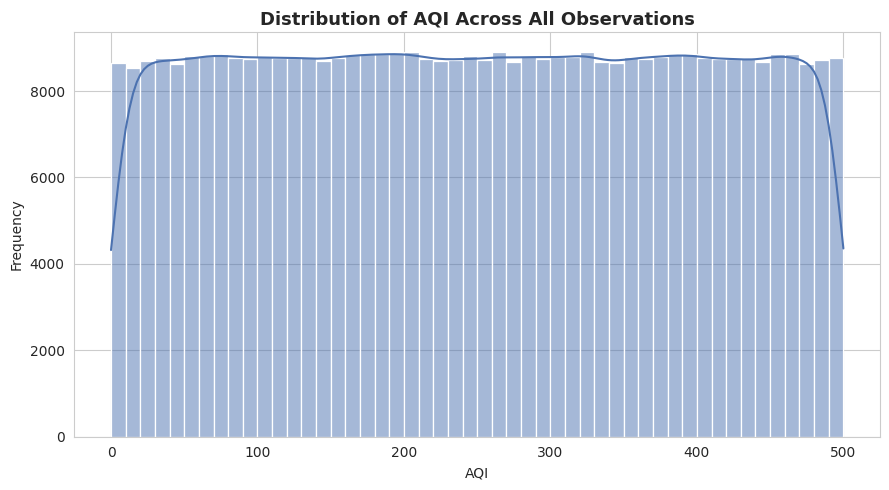

In [ ]:
if HAS_AQI:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(df["AQI"], bins=50, kde=True, color="#4C72B0", ax=ax)
    ax.set_title("Distribution of AQI Across All Observations", fontsize=13, fontweight="bold")
    ax.set_xlabel("AQI")
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("AQI column not found -- skipping.")

### Visualization 2 -- AQI Category Distribution

/tmp/ipykernel_1854/3318316635.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="AQI_Bucket", data=df, order=order, palette="RdYlGn_r", ax=ax)


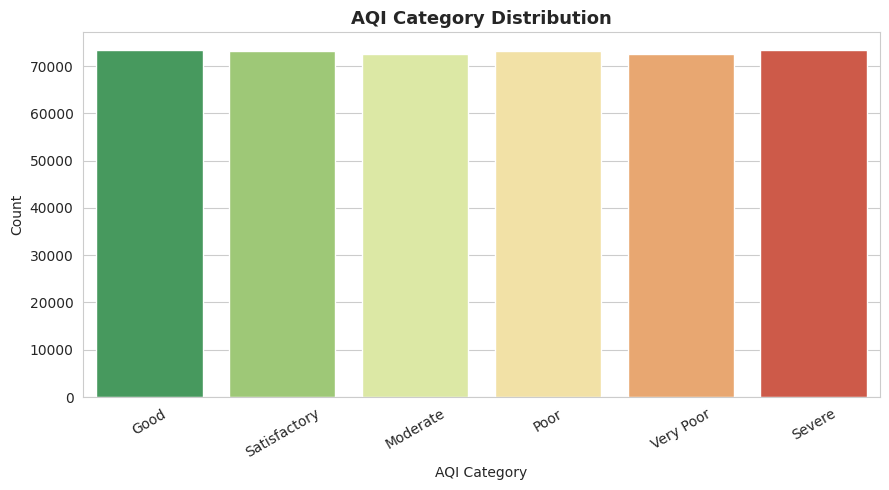

In [ ]:
if HAS_BUCKET:
    order = [c for c in ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"] if c in df["AQI_Bucket"].unique()]
    order += [c for c in df["AQI_Bucket"].unique() if c not in order]
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.countplot(x="AQI_Bucket", data=df, order=order, palette="RdYlGn_r", ax=ax)
    ax.set_title("AQI Category Distribution", fontsize=13, fontweight="bold")
    ax.set_xlabel("AQI Category")
    ax.set_ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No AQI category column found -- skipping.")

### Visualization 3 -- City-wise Average AQI (Top / Bottom N)

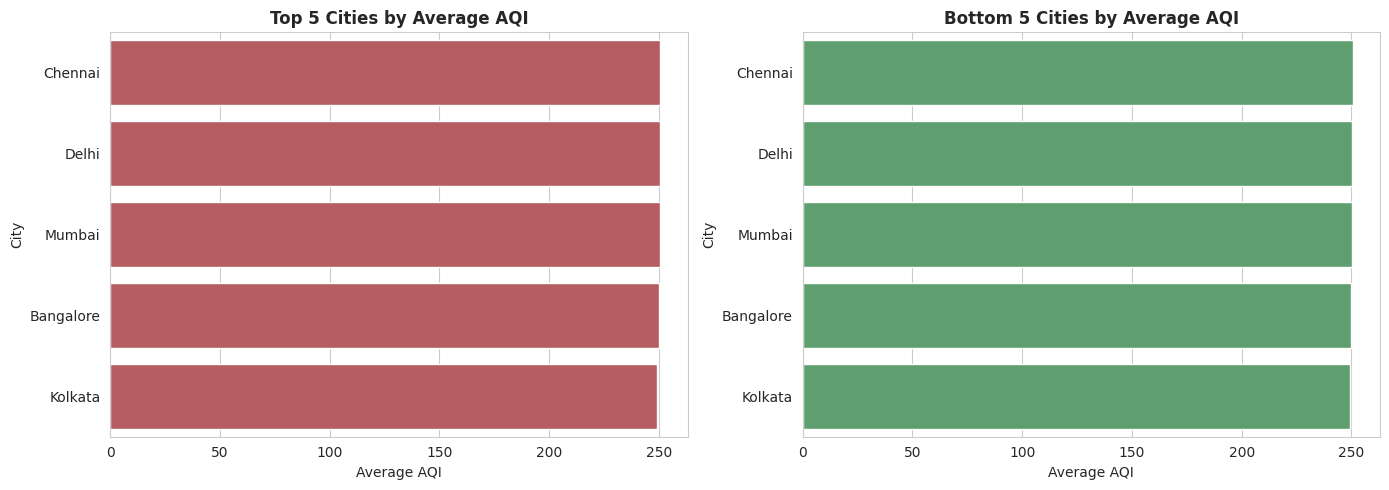

In [ ]:
if HAS_CITY and HAS_AQI:
    MIN_OBS = 30  # minimum observations for a city to be ranked fairly
    city_counts = df["City"].value_counts()
    eligible_cities = city_counts[city_counts >= MIN_OBS].index
    city_avg = df[df["City"].isin(eligible_cities)].groupby("City")["AQI"].mean().sort_values(ascending=False)

    top_n = min(10, len(city_avg))
    top_cities = city_avg.head(top_n)
    bottom_cities = city_avg.tail(top_n)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[0], color="#C44E52")
    axes[0].set_title(f"Top {top_n} Cities by Average AQI", fontweight="bold")
    axes[0].set_xlabel("Average AQI")

    sns.barplot(x=bottom_cities.values, y=bottom_cities.index, ax=axes[1], color="#55A868")
    axes[1].set_title(f"Bottom {top_n} Cities by Average AQI", fontweight="bold")
    axes[1].set_xlabel("Average AQI")

    plt.tight_layout()
    plt.show()
else:
    print("City and/or AQI unavailable -- skipping.")

### Visualization 4 -- AQI Trend Over Time

/tmp/ipykernel_1854/2279047779.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_trend = df.set_index("Date").resample("M")["AQI"].mean()


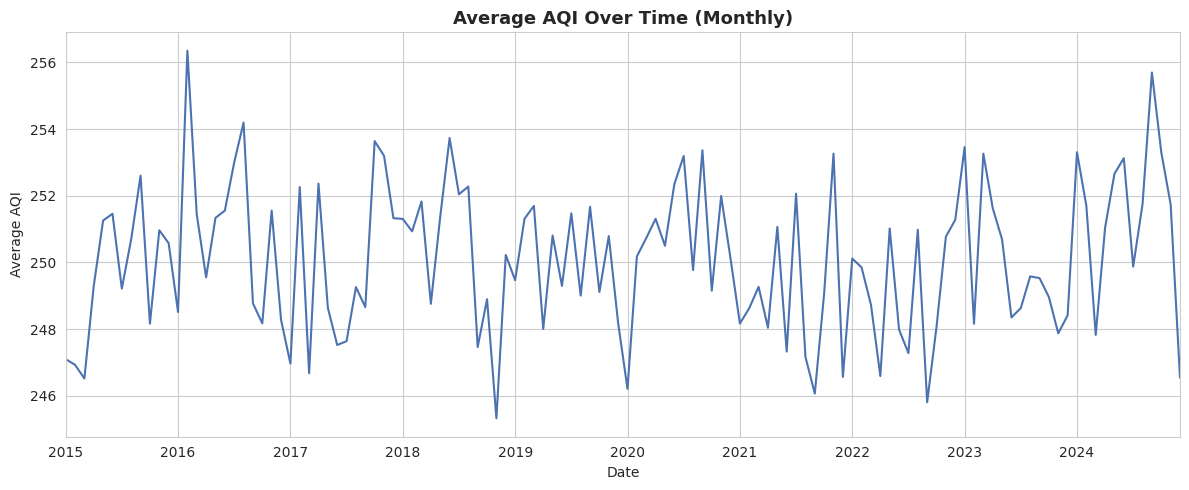

In [ ]:
if HAS_DATE and HAS_AQI:
    monthly_trend = df.set_index("Date").resample("M")["AQI"].mean()
    fig, ax = plt.subplots(figsize=(12, 5))
    monthly_trend.plot(ax=ax, color="#4C72B0")
    ax.set_title("Average AQI Over Time (Monthly)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Date")
    ax.set_ylabel("Average AQI")
    plt.tight_layout()
    plt.show()
else:
    print("Date and/or AQI unavailable -- skipping.")

### Visualization 5 -- Monthly AQI Pattern

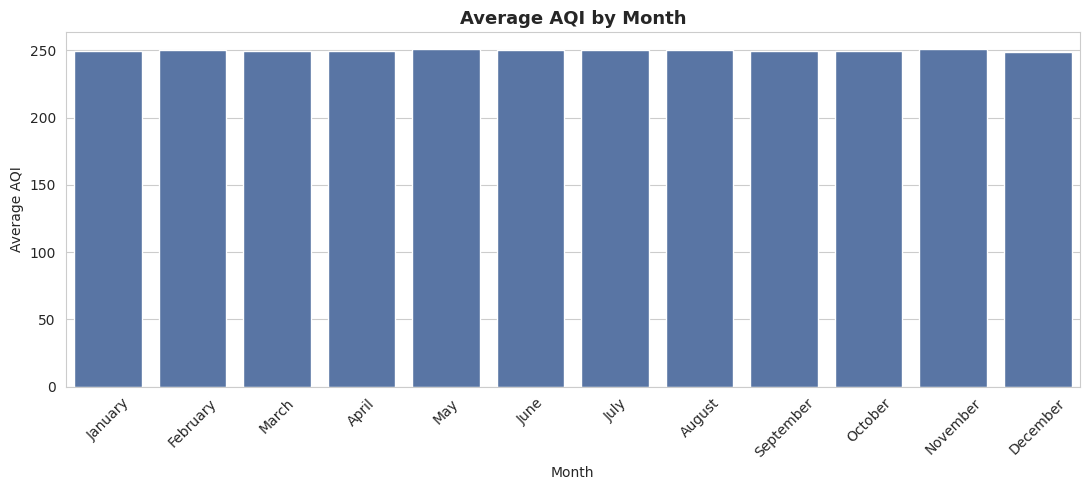

In [ ]:
if HAS_DATE and HAS_AQI:
    month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
    monthly_avg = df.groupby("Month_Name")["AQI"].mean().reindex(month_order)
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.barplot(x=monthly_avg.index, y=monthly_avg.values, color="#4C72B0", ax=ax)
    ax.set_title("Average AQI by Month", fontsize=13, fontweight="bold")
    ax.set_xlabel("Month")
    ax.set_ylabel("Average AQI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Visualization 6 -- Seasonal AQI Pattern

/tmp/ipykernel_1854/2370974656.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Season", y="AQI", data=df, order=season_order, palette="coolwarm", ax=ax)


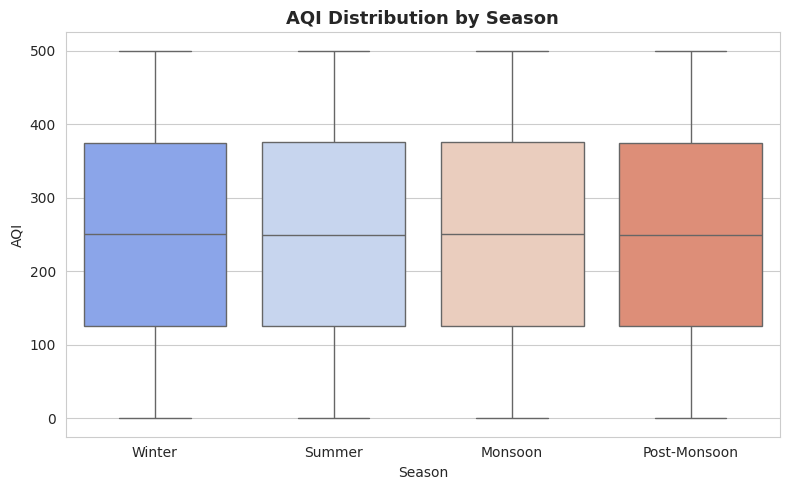

In [ ]:
if HAS_DATE and HAS_AQI:
    season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(x="Season", y="AQI", data=df, order=season_order, palette="coolwarm", ax=ax)
    ax.set_title("AQI Distribution by Season", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

### Visualization 7 -- PM2.5 vs AQI

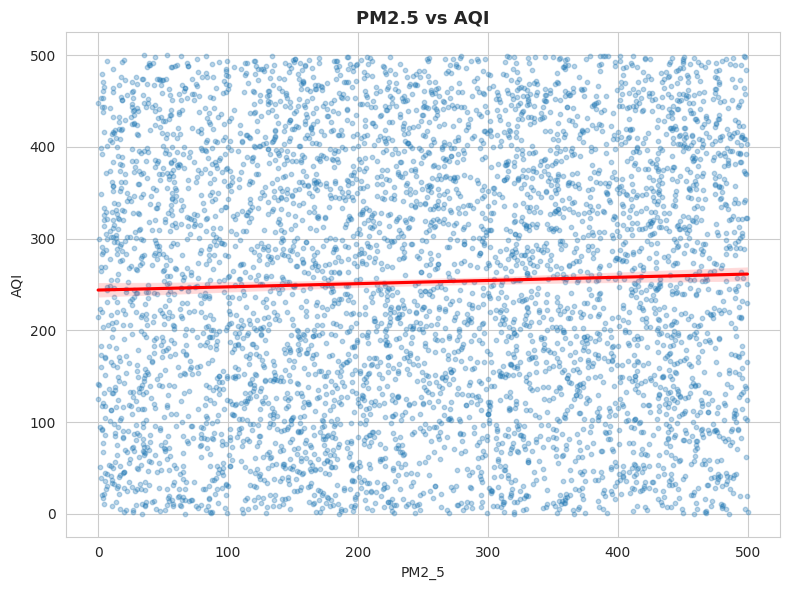

In [ ]:
if "PM2_5" in df.columns and HAS_AQI:
    fig, ax = plt.subplots(figsize=(8, 6))
    sample = df.sample(min(5000, len(df)), random_state=42)
    sns.regplot(x="PM2_5", y="AQI", data=sample, scatter_kws={"alpha":0.3, "s":10}, line_kws={"color":"red"}, ax=ax)
    ax.set_title("PM2.5 vs AQI", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("PM2_5 column not found -- skipping.")

### Visualization 8 -- PM10 vs AQI

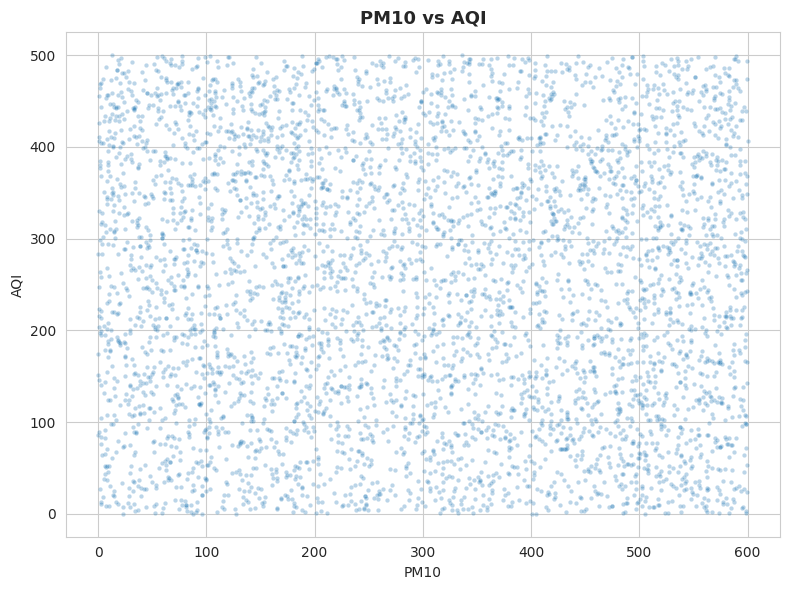

In [ ]:
if "PM10" in df.columns and HAS_AQI:
    fig, ax = plt.subplots(figsize=(8, 6))
    sample = df.sample(min(5000, len(df)), random_state=42)
    sns.scatterplot(x="PM10", y="AQI", data=sample, alpha=0.3, s=10, ax=ax)
    ax.set_title("PM10 vs AQI", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("PM10 column not found -- skipping.")

### Visualization 9 -- Correlation Heatmap

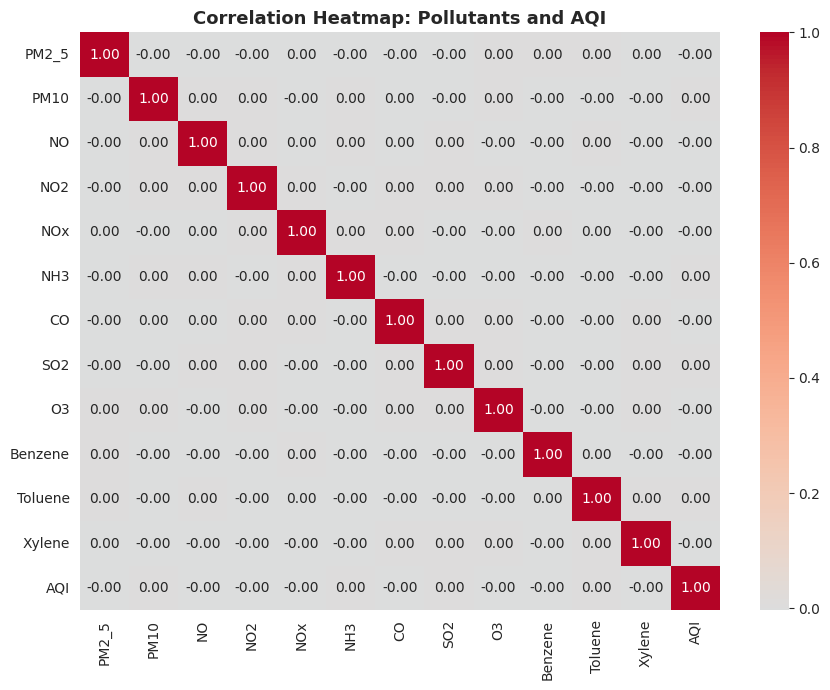

In [ ]:
corr_cols = POLLUTANTS + (["AQI"] if HAS_AQI else [])
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title("Correlation Heatmap: Pollutants and AQI", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

### Visualization 10 -- Average Pollutant Concentrations

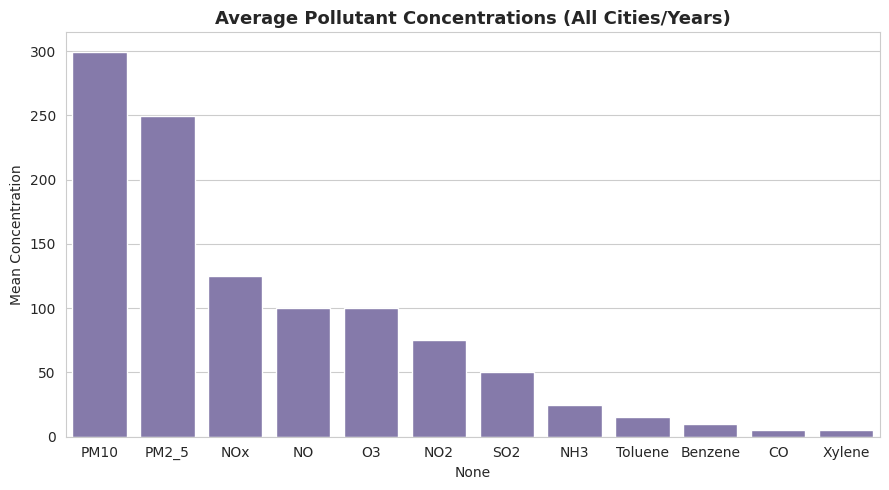

In [ ]:
if POLLUTANTS:
    pollutant_means = df[POLLUTANTS].mean().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(x=pollutant_means.index, y=pollutant_means.values, color="#8172B2", ax=ax)
    ax.set_title("Average Pollutant Concentrations (All Cities/Years)", fontsize=13, fontweight="bold")
    ax.set_ylabel("Mean Concentration")
    plt.tight_layout()
    plt.show()

### Visualization 11 -- City x Pollution Analysis

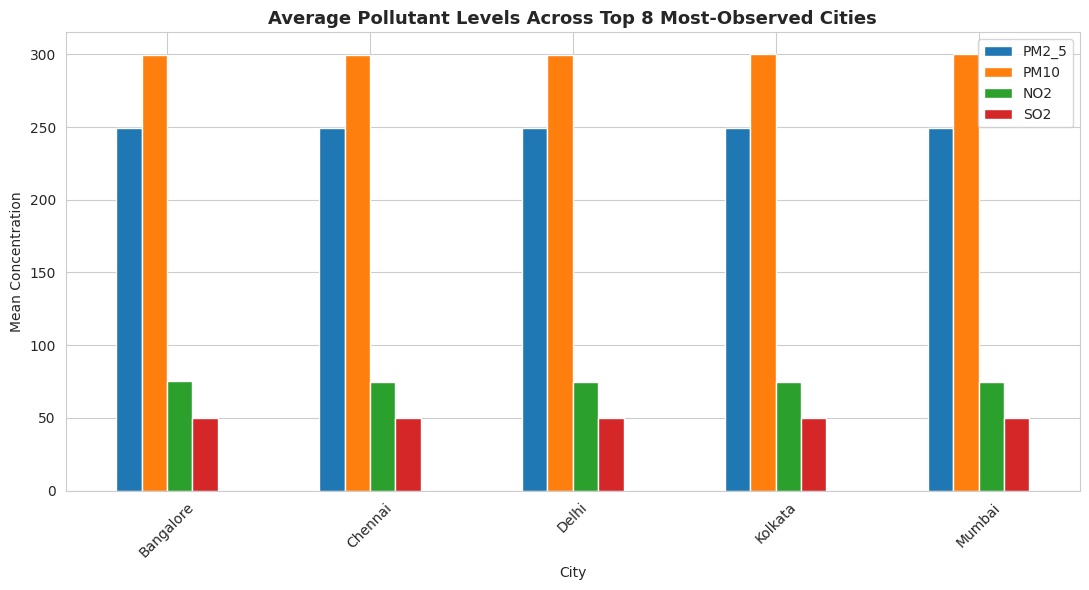

In [ ]:
if HAS_CITY and POLLUTANTS:
    key_pollutants = [p for p in ["PM2_5", "PM10", "NO2", "SO2"] if p in POLLUTANTS][:4]
    if key_pollutants:
        top_cities_list = df["City"].value_counts().head(8).index
        subset = df[df["City"].isin(top_cities_list)]
        city_poll_avg = subset.groupby("City")[key_pollutants].mean()
        fig, ax = plt.subplots(figsize=(11, 6))
        city_poll_avg.plot(kind="bar", ax=ax)
        ax.set_title("Average Pollutant Levels Across Top 8 Most-Observed Cities", fontsize=13, fontweight="bold")
        ax.set_ylabel("Mean Concentration")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

### Visualization 12 -- AQI Category Over Time (Percentage Stacked)

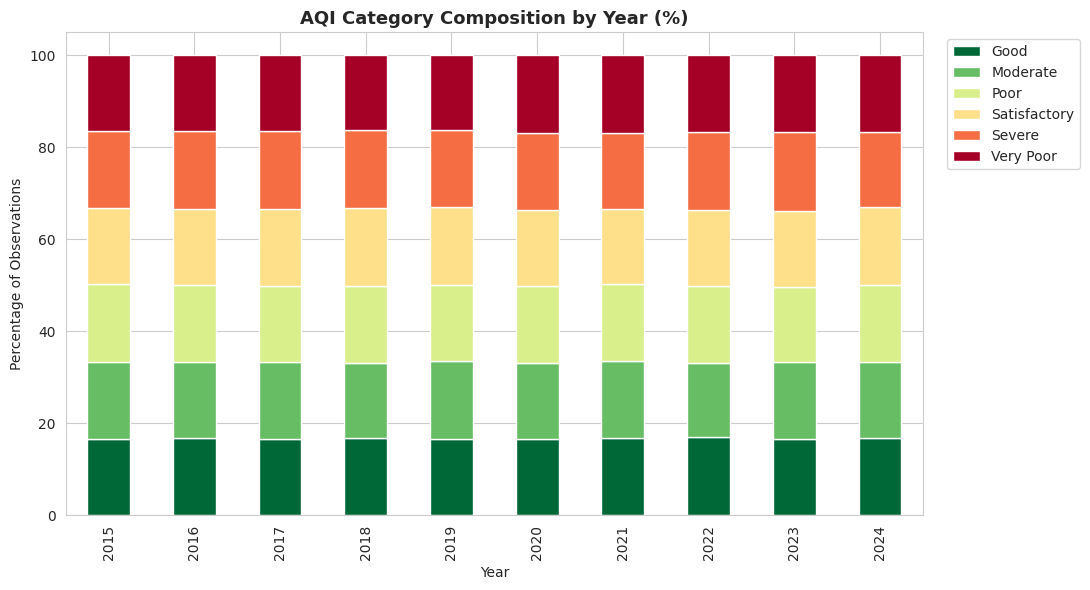

In [ ]:
if HAS_DATE and HAS_BUCKET:
    ct = pd.crosstab(df["Year"], df["AQI_Bucket"], normalize="index") * 100
    fig, ax = plt.subplots(figsize=(11, 6))
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn_r")
    ax.set_title("AQI Category Composition by Year (%)", fontsize=13, fontweight="bold")
    ax.set_ylabel("Percentage of Observations")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Date and/or AQI category unavailable -- skipping.")

## 16. Important Discussion: AQI Data Leakage

**This section is critical to interpreting every result that follows.**

The AQI is generally **calculated directly from pollutant concentrations** using a documented sub-index/aggregation formula (e.g. by CPCB in India). This means:

```
Pollutants  -->  AQI
```

is, at least partly, a **mathematically/deterministically related** transformation rather than an independent phenomenon that must be "discovered." As a result:

- A model that predicts **same-timestamp AQI from same-timestamp pollutant readings** (Sections 19–24) may achieve very high accuracy — but this reflects the model recovering a known formula-like relationship, **not** a demonstration that the model can forecast *future*, not-yet-observed air quality.
- This is fundamentally different from **future AQI forecasting** (Section 32), where the model must predict AQI at a time point using only *past* information, with no access to concurrent pollutant readings for that same period.

We therefore explicitly distinguish, throughout this notebook:

| Task | What is predicted | What is used as input | Interpretation |
|---|---|---|---|
| **Current-condition estimation** (Sections 19–29) | AQI / AQI category *at time t* | Pollutants *at time t* (+ City, temporal features) | Demonstrates that pollutant readings encode AQI-relevant information; a sanity check and a way to compare feature groups (RQ3–RQ6), **not** a forecast |
| **Future forecasting** (Section 32) | AQI *at time t* | Only data known **before** time t (lagged AQI/pollutants) | A genuine test of whether *history* can predict the *future* |

No result in this notebook should be read as claiming the ability to forecast pollution days or weeks in advance unless it comes from the explicitly labeled temporal-forecasting experiment.

## 17. Feature Engineering

In [ ]:
# Base feature set used for the "current-condition" regression/classification tasks.
# AQI itself and AQI_Bucket are explicitly EXCLUDED as predictors of AQI (Section 21/25 handle
# AQI_Bucket / AQI as targets, never as leaking predictors of each other -- see Section 18).

base_numeric_features = list(POLLUTANTS)
base_categorical_features = []
if HAS_CITY:
    base_categorical_features.append("City")

temporal_features_numeric = []
temporal_features_categorical = []
if HAS_DATE:
    temporal_features_numeric = ["Year", "Month", "Quarter", "Day_of_Week"]
    temporal_features_categorical = ["Season"]

print("Base numeric (pollutant) features:", base_numeric_features)
print("Base categorical features:", base_categorical_features)
print("Temporal numeric features:", temporal_features_numeric)
print("Temporal categorical features:", temporal_features_categorical)

Base numeric (pollutant) features: ['PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Base categorical features: ['City']
Temporal numeric features: ['Year', 'Month', 'Quarter', 'Day_of_Week']
Temporal categorical features: ['Season']


## 18. Target-Leakage Rule (Applied Throughout)

- When predicting **AQI** (regression): `AQI_Bucket`/`AQI_Category` is **never** used as a predictor, because it is derived from AQI itself.
- When predicting **AQI_Bucket** (classification): raw **AQI** is **never** used as a predictor, for the same reason.
- `Date` (the raw string/datetime) is never fed directly into a model; only derived calendar features (`Year`, `Month`, `Quarter`, `Day_of_Week`, `Season`) are used.

This rule is enforced explicitly in every modeling section below.

## 19. AQI Regression: Setup, Train-Test Split, and Preprocessing Pipeline

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

if not HAS_AQI:
    print("No AQI column found -- regression sections cannot be executed on this dataset.")
else:
    reg_numeric_features = base_numeric_features + temporal_features_numeric
    reg_categorical_features = base_categorical_features + temporal_features_categorical

    model_df = df.dropna(subset=["AQI"]).copy()

    X = model_df[reg_numeric_features + reg_categorical_features]
    y = model_df["AQI"]

    # Standard (non-temporal) split: random 80/20, used for "current-condition estimation".
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

    print("Regression numeric features:", reg_numeric_features)
    print("Regression categorical features:", reg_categorical_features)
    print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, reg_numeric_features),
        ("cat", categorical_transformer, reg_categorical_features),
    ])

    print("\nPreprocessing pipeline constructed (median imputation + scaling for numeric; "
          "most-frequent imputation + one-hot encoding for categorical).")

Regression numeric features: ['PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Year', 'Month', 'Quarter', 'Day_of_Week']
Regression categorical features: ['City', 'Season']
Train shape: (350596, 18)  Test shape: (87649, 18)

Preprocessing pipeline constructed (median imputation + scaling for numeric; most-frequent imputation + one-hot encoding for categorical).


## 20. AQI Regression Models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

regression_results = {}
regression_fitted_pipelines = {}

if HAS_AQI:
    for name, model in regression_models.items():
        pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
        pipe.fit(X_train, y_train)
        preds = pipe.predict(X_test)

        mae = mean_absolute_error(y_test, preds)
        mse = mean_squared_error(y_test, preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, preds)

        regression_results[name] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}
        regression_fitted_pipelines[name] = pipe
        print(f"{name:20s} | MAE={mae:8.3f}  RMSE={rmse:8.3f}  R2={r2:6.4f}")

Linear Regression    | MAE= 124.770  RMSE= 144.059  R2=-0.0003
Decision Tree        | MAE= 167.959  RMSE= 205.721  R2=-1.0399


## 21. Regression Evaluation and Model Comparison

In [ ]:
if HAS_AQI:
    regression_comparison = pd.DataFrame(regression_results).T.round(4)
    regression_comparison = regression_comparison.sort_values("RMSE")
    print(regression_comparison)

    best_regression_model_name = regression_comparison["RMSE"].idxmin()
    print(f"\nBest regression model (lowest RMSE): {best_regression_model_name}")

### Visualization 14 -- Actual vs Predicted AQI (Best Model)

In [ ]:
if HAS_AQI:
    best_reg_pipe = regression_fitted_pipelines[best_regression_model_name]
    best_preds = best_reg_pipe.predict(X_test)

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(y_test, best_preds, alpha=0.3, s=12, color="#4C72B0")
    lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_xlabel("Actual AQI")
    ax.set_ylabel("Predicted AQI")
    ax.set_title(f"Actual vs Predicted AQI -- {best_regression_model_name}", fontsize=13, fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.show()

### Visualization 15 -- Regression Model Performance Comparison

In [ ]:
if HAS_AQI:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    regression_comparison["MAE"].plot(kind="bar", ax=axes[0], color="#4C72B0", title="MAE (lower is better)")
    regression_comparison["RMSE"].plot(kind="bar", ax=axes[1], color="#C44E52", title="RMSE (lower is better)")
    regression_comparison["R2"].plot(kind="bar", ax=axes[2], color="#55A868", title="R2 (higher is better)")
    for ax in axes:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 22. AQI Category Classification: Setup

In [ ]:
def bucket_from_aqi(aqi):
    # CPCB-style AQI category thresholds, used only as a fallback if AQI_Bucket does not exist.
    if pd.isna(aqi):
        return np.nan
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

if HAS_BUCKET:
    target_bucket_col = "AQI_Bucket"
    print("Using existing AQI_Bucket column as the classification target.")
    clf_source_df = df[df["AQI_Bucket"].notna() & (df["AQI_Bucket"] != "Unknown")].copy()
elif HAS_AQI:
    print("No AQI_Bucket column found. Deriving categories from AQI using documented CPCB breakpoints "
          "(Good <=50, Satisfactory <=100, Moderate <=200, Poor <=300, Very Poor <=400, Severe >400).")
    df["AQI_Bucket_Derived"] = df["AQI"].apply(bucket_from_aqi)
    target_bucket_col = "AQI_Bucket_Derived"
    clf_source_df = df[df[target_bucket_col].notna()].copy()
else:
    target_bucket_col = None
    clf_source_df = None
    print("Neither AQI nor AQI_Bucket found -- classification section cannot be executed.")

if target_bucket_col:
    print("\nClass distribution:")
    counts = clf_source_df[target_bucket_col].value_counts()
    pct = (counts / len(clf_source_df) * 100).round(2)
    print(pd.DataFrame({"count": counts, "percent": pct}))

**Leakage rule applied:** raw `AQI` is **excluded** from the predictor set for this task, since the category is derived directly from AQI (whether it came pre-labeled or was derived above).

In [ ]:
if target_bucket_col:
    clf_numeric_features = base_numeric_features + temporal_features_numeric
    clf_categorical_features = base_categorical_features + temporal_features_categorical

    Xc = clf_source_df[clf_numeric_features + clf_categorical_features]
    yc = clf_source_df[target_bucket_col]

    Xc_train, Xc_test, yc_train, yc_test = train_test_split(
        Xc, yc, test_size=0.20, random_state=42, stratify=yc
    )

    clf_preprocessor = ColumnTransformer(transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), clf_numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), clf_categorical_features),
    ])

    print("Classification train shape:", Xc_train.shape, " test shape:", Xc_test.shape)

## 23. Class Imbalance Check

In [ ]:
if target_bucket_col:
    fig, ax = plt.subplots(figsize=(9, 5))
    order = [c for c in ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"] if c in yc.unique()]
    order += [c for c in yc.unique() if c not in order]
    sns.countplot(x=yc, order=order, palette="RdYlGn_r", ax=ax)
    ax.set_title("AQI Category Distribution (Classification Target)", fontweight="bold")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    imbalance_ratio = yc.value_counts().max() / yc.value_counts().min()
    print(f"Imbalance ratio (largest class / smallest class): {imbalance_ratio:.1f}x")
    if imbalance_ratio > 3:
        print("Classes are notably imbalanced -> using class_weight='balanced' where supported, "
              "and reporting macro-averaged metrics (which do not favor the majority class).")

## 24. AQI Category Classification Models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),  # no native class_weight support
}

classification_results = {}
classification_fitted_pipelines = {}

if target_bucket_col:
    for name, model in classification_models.items():
        pipe = Pipeline(steps=[("preprocessor", clf_preprocessor), ("model", model)])
        pipe.fit(Xc_train, yc_train)
        preds = pipe.predict(Xc_test)

        acc = accuracy_score(yc_test, preds)
        macro_f1 = f1_score(yc_test, preds, average="macro")
        weighted_f1 = f1_score(yc_test, preds, average="weighted")
        precision_macro = precision_score(yc_test, preds, average="macro", zero_division=0)
        recall_macro = recall_score(yc_test, preds, average="macro", zero_division=0)

        classification_results[name] = {
            "Accuracy": acc, "Precision(macro)": precision_macro, "Recall(macro)": recall_macro,
            "F1(macro)": macro_f1, "F1(weighted)": weighted_f1
        }
        classification_fitted_pipelines[name] = pipe
        print(f"{name:20s} | Acc={acc:.4f}  MacroF1={macro_f1:.4f}  WeightedF1={weighted_f1:.4f}")

## 25. Classification Evaluation

**Note on averaging:** with more than two classes, `macro` averaging computes the metric independently for each class and takes the unweighted mean (treats every class, including rare ones like "Severe", as equally important) while `weighted` averaging weights each class by its support (better reflects overall accuracy but can hide poor performance on rare-but-important classes). Both are reported; macro-F1 is used as the primary comparison metric because correctly identifying rare *severe* pollution events matters more than the imbalance-favoring weighted score.

In [ ]:
if target_bucket_col:
    classification_comparison = pd.DataFrame(classification_results).T.round(4)
    classification_comparison = classification_comparison.sort_values("F1(macro)", ascending=False)
    print(classification_comparison)

    best_classification_model_name = classification_comparison["F1(macro)"].idxmax()
    print(f"\nBest classification model (highest macro F1): {best_classification_model_name}")

In [ ]:
if target_bucket_col:
    best_clf_pipe = classification_fitted_pipelines[best_classification_model_name]
    best_clf_preds = best_clf_pipe.predict(Xc_test)
    print(classification_report(yc_test, best_clf_preds, zero_division=0))

In [ ]:
if target_bucket_col:
    labels_order = [c for c in ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"] if c in yc.unique()]
    labels_order += [c for c in yc.unique() if c not in labels_order]

    cm = confusion_matrix(yc_test, best_clf_preds, labels=labels_order)
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Confusion Matrix -- {best_classification_model_name}", fontweight="bold")
    plt.tight_layout()
    plt.show()

## 26. RQ4 -- Does Using Multiple Pollutants Improve AQI Prediction?

We hold the model type fixed (Random Forest -- generally a strong, robust default) and vary only the **feature set**, to isolate the effect of adding more pollutant information.

In [ ]:
if HAS_AQI:
    major_pollutants = [p for p in ["PM2_5", "PM10", "NO2", "SO2", "CO", "O3"] if p in POLLUTANTS]

    feature_sets = {}
    if "PM2_5" in POLLUTANTS:
        feature_sets["PM2.5 only"] = ["PM2_5"]
    if "PM2_5" in POLLUTANTS and "PM10" in POLLUTANTS:
        feature_sets["PM2.5 + PM10"] = ["PM2_5", "PM10"]
    if len(major_pollutants) > 2:
        feature_sets["Major pollutants"] = major_pollutants
    feature_sets["All available pollutants"] = list(POLLUTANTS)

    # de-duplicate identical feature sets (can happen on datasets with few pollutant columns)
    seen = set()
    feature_sets = {k: v for k, v in feature_sets.items() if tuple(sorted(v)) not in seen and not seen.add(tuple(sorted(v)))}

    print("Feature sets to compare:")
    for k, v in feature_sets.items():
        print(f"  {k}: {v}")

    rq4_results = {}
    for exp_name, feats in feature_sets.items():
        Xe = model_df[feats]
        ye = model_df["AQI"]
        Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.20, random_state=42)

        pre = ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), feats)])
        pipe = Pipeline([("preprocessor", pre), ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))])
        pipe.fit(Xe_train, ye_train)
        preds = pipe.predict(Xe_test)

        rq4_results[exp_name] = {
            "n_features": len(feats),
            "MAE": mean_absolute_error(ye_test, preds),
            "RMSE": np.sqrt(mean_squared_error(ye_test, preds)),
            "R2": r2_score(ye_test, preds),
        }

    rq4_df = pd.DataFrame(rq4_results).T.round(4)
    print(rq4_df)

In [ ]:
if HAS_AQI:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(x=rq4_df.index, y=rq4_df["R2"], color="#4C72B0", ax=ax)
    ax.set_title("RQ4: Effect of Pollutant Feature Set on AQI Prediction (R2)", fontweight="bold")
    ax.set_ylabel("R2 (higher = better)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

**Answer (RQ4):** *See the R2/RMSE trend in the table and chart above.* If R2 increases (and RMSE decreases) monotonically from "PM2.5 only" toward "All available pollutants," this supports that additional pollutant information improves prediction, consistent with AQI typically being computed from the single worst/dominant sub-index pollutant among several measured — meaning more pollutants raise the chance of capturing whichever one is currently dominant. The exact magnitude of the improvement should be read from the executed results, not assumed in advance.

## 27. RQ5 -- Does Adding City Information Improve AQI Prediction?

In [ ]:
if HAS_AQI and HAS_CITY:
    rq5_results = {}

    configs = {
        "Pollutants only": (list(POLLUTANTS), []),
        "Pollutants + City": (list(POLLUTANTS), ["City"]),
    }

    for exp_name, (num_feats, cat_feats) in configs.items():
        Xe = model_df[num_feats + cat_feats]
        ye = model_df["AQI"]
        Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.20, random_state=42)

        transformers = [("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_feats)]
        if cat_feats:
            transformers.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_feats))
        pre = ColumnTransformer(transformers)

        pipe = Pipeline([("preprocessor", pre), ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))])
        pipe.fit(Xe_train, ye_train)
        preds = pipe.predict(Xe_test)

        rq5_results[exp_name] = {
            "MAE": mean_absolute_error(ye_test, preds),
            "RMSE": np.sqrt(mean_squared_error(ye_test, preds)),
            "R2": r2_score(ye_test, preds),
        }

    rq5_df = pd.DataFrame(rq5_results).T.round(4)
    print(rq5_df)
else:
    print("City column not available -- RQ5 experiment skipped.")

**Answer (RQ5):** Compare the R2/RMSE of "Pollutants only" vs "Pollutants + City" above. An improvement suggests city identity captures location-specific factors (traffic density, industrial activity, geography, local monitoring-station characteristics) not fully explained by the pollutant readings alone. No improvement suggests pollutant concentrations already summarize most of the location-relevant signal.

## 28. Feature Importance

In [ ]:
if HAS_AQI:
    best_reg_pipe = regression_fitted_pipelines[best_regression_model_name]
    fitted_model = best_reg_pipe.named_steps["model"]

    # Recover feature names after preprocessing (numeric passthrough + one-hot expanded categorical)
    feature_names = list(reg_numeric_features)
    if reg_categorical_features:
        ohe = best_reg_pipe.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
        feature_names += list(ohe.get_feature_names_out(reg_categorical_features))

    if hasattr(fitted_model, "feature_importances_"):
        importances = fitted_model.feature_importances_
        fi_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
        top_fi = fi_df.head(15)

        fig, ax = plt.subplots(figsize=(9, 7))
        sns.barplot(x="importance", y="feature", data=top_fi, color="#4C72B0", ax=ax)
        ax.set_title(f"Top Feature Importances -- {best_regression_model_name}", fontweight="bold")
        plt.tight_layout()
        plt.show()

        print(top_fi)
    else:
        print(f"{best_regression_model_name} does not expose native feature_importances_; "
              "see permutation importance below instead.")

In [ ]:
if HAS_AQI:
    from sklearn.inspection import permutation_importance

    perm_result = permutation_importance(
        best_reg_pipe, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1
    )
    perm_df = pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": perm_result.importances_mean,
        "importance_std": perm_result.importances_std,
    }).sort_values("importance_mean", ascending=False)

    print("Permutation importance (on original, pre-encoding feature columns):")
    print(perm_df.head(15))

**Answer (RQ3):** The strongest predictors are those ranked highest above. **Predictive importance does not imply causal influence** — a feature can be highly predictive because it is correlated with, or partially derived from, the target's underlying computation (see Section 16), not because changing it would causally change AQI in reality.

## 29. City Analysis (RQ6)

In [ ]:
if HAS_CITY:
    MIN_OBS = 30
    counts = df["City"].value_counts()
    eligible = counts[counts >= MIN_OBS].index
    print(f"Ranking restricted to cities with >= {MIN_OBS} observations "
          f"({len(eligible)} of {df['City'].nunique()} cities qualify).")

    sub = df[df["City"].isin(eligible)]

    if HAS_AQI:
        top10_aqi = sub.groupby("City")["AQI"].mean().sort_values(ascending=False).head(10)
        bottom10_aqi = sub.groupby("City")["AQI"].mean().sort_values(ascending=True).head(10)
        print("\nTop 10 cities by average AQI:")
        print(top10_aqi.round(2))
        print("\nBottom 10 cities by average AQI:")
        print(bottom10_aqi.round(2))

    if "PM2_5" in POLLUTANTS:
        top10_pm25 = sub.groupby("City")["PM2_5"].mean().sort_values(ascending=False).head(10)
        print("\nTop 10 cities by average PM2.5:")
        print(top10_pm25.round(2))

    if "PM10" in POLLUTANTS:
        top10_pm10 = sub.groupby("City")["PM10"].mean().sort_values(ascending=False).head(10)
        print("\nTop 10 cities by average PM10:")
        print(top10_pm10.round(2))
else:
    print("City column not available -- city analysis skipped.")

**Answer (RQ6):** The cities listed at the top of the "average AQI" ranking above have the highest pollution levels in this dataset (subject to the minimum-observation threshold, which prevents a thinly-sampled city from dominating the ranking by chance).

## 30. Seasonal Analysis (RQ7)

In [ ]:
if HAS_DATE:
    season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]
    agg_cols = ([ "AQI"] if HAS_AQI else []) + POLLUTANTS
    seasonal_stats = df.groupby("Season")[agg_cols].mean().reindex(season_order).round(2)
    print("Seasonal averages:")
    print(seasonal_stats)

    if HAS_AQI:
        highest_season = seasonal_stats["AQI"].idxmax()
        lowest_season = seasonal_stats["AQI"].idxmin()
        print(f"\nHighest-pollution season (by mean AQI): {highest_season}")
        print(f"Lowest-pollution season (by mean AQI): {lowest_season}")
else:
    print("Date column not available -- seasonal analysis skipped.")

**Answer (RQ7):** The season identified as "highest-pollution" above shows the greatest average AQI/pollutant load; this is an empirical result from the actual data (commonly Winter in North Indian cities due to temperature inversion, crop-residue burning, and reduced wind dispersion — but this must be confirmed against the printed output above rather than assumed).

## 31. Yearly Analysis (RQ8)

In [ ]:
if HAS_DATE:
    yearly_mean = df.groupby("Year")["AQI"].mean().round(2) if HAS_AQI else None
    yearly_median = df.groupby("Year")["AQI"].median().round(2) if HAS_AQI else None
    yearly_obs_count = df.groupby("Year").size()

    if HAS_AQI:
        yearly_table = pd.DataFrame({"mean_AQI": yearly_mean, "median_AQI": yearly_median, "n_observations": yearly_obs_count})
        print(yearly_table)

        fig, ax = plt.subplots(figsize=(10, 5))
        yearly_mean.plot(marker="o", ax=ax, color="#4C72B0", label="Mean AQI")
        yearly_median.plot(marker="s", ax=ax, color="#C44E52", label="Median AQI")
        ax.set_title("Yearly AQI Trend", fontweight="bold")
        ax.set_ylabel("AQI")
        ax.legend()
        plt.tight_layout()
        plt.show()

    print("\nObservation count per year (checking for monitoring-coverage changes):")
    print(yearly_obs_count)

    if HAS_BUCKET or "AQI_Bucket_Derived" in df.columns:
        bucket_col_for_years = "AQI_Bucket" if HAS_BUCKET else "AQI_Bucket_Derived"
        yearly_bucket_pct = pd.crosstab(df["Year"], df[bucket_col_for_years], normalize="index") * 100
        print("\nAQI category composition by year (%):")
        print(yearly_bucket_pct.round(1))
else:
    print("Date column not available -- yearly analysis skipped.")

**Answer (RQ8):** Read the trend directly from the "Mean AQI"/"Median AQI" line chart above: a rising line indicates worsening pollution over the years represented, a falling line indicates improvement, and a flat line indicates relative stability. **Caveat:** if `n_observations` per year varies substantially (printed above), differences across years may partly reflect changes in monitoring-station coverage rather than a true change in air quality — this is flagged explicitly as a limitation (Section 36).

## 32. Poor-Air-Quality Early-Warning Model (RQ9)

In [ ]:
if target_bucket_col:
    poor_or_worse = {"Poor", "Very Poor", "Severe"}
    present_poor_categories = [c for c in poor_or_worse if c in clf_source_df[target_bucket_col].unique()]
    print("Categories treated as 'Poor or worse' (label = 1):", present_poor_categories)
    print("All other categories treated as label = 0.")

    if present_poor_categories:
        clf_source_df["EarlyWarning"] = clf_source_df[target_bucket_col].isin(present_poor_categories).astype(int)
        print("\nEarly-warning label distribution:")
        print(clf_source_df["EarlyWarning"].value_counts())
        print((clf_source_df["EarlyWarning"].value_counts(normalize=True) * 100).round(2))
    else:
        print("No 'Poor'/'Very Poor'/'Severe' categories present in this dataset -- "
              "early-warning binary target cannot be constructed as specified.")
else:
    print("No classification target available -- early-warning section skipped.")

In [ ]:
if target_bucket_col and present_poor_categories:
    Xw = clf_source_df[clf_numeric_features + clf_categorical_features]
    yw = clf_source_df["EarlyWarning"]

    Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.20, random_state=42, stratify=yw)

    warn_preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), clf_numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), clf_categorical_features),
    ])

    warn_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced")
    warn_pipe = Pipeline([("preprocessor", warn_preprocessor), ("model", warn_model)])
    warn_pipe.fit(Xw_train, yw_train)

    warn_preds = warn_pipe.predict(Xw_test)
    warn_proba = warn_pipe.predict_proba(Xw_test)[:, 1]

    from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

    ew_precision = precision_score(yw_test, warn_preds, zero_division=0)
    ew_recall = recall_score(yw_test, warn_preds, zero_division=0)
    ew_f1 = f1_score(yw_test, warn_preds, zero_division=0)
    ew_auc = roc_auc_score(yw_test, warn_proba)

    print(f"Precision: {ew_precision:.4f}")
    print(f"Recall:    {ew_recall:.4f}")
    print(f"F1-score:  {ew_f1:.4f}")
    print(f"ROC-AUC:   {ew_auc:.4f}")

    cm_warn = confusion_matrix(yw_test, warn_preds)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_warn, annot=True, fmt="d", cmap="Reds",
                xticklabels=["Not Poor+", "Poor+"], yticklabels=["Not Poor+", "Poor+"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Early-Warning Confusion Matrix", fontweight="bold")
    plt.tight_layout()
    plt.show()

**Why recall matters most for early warning:** in a public-health warning system, a **false negative** (predicting "safe" when conditions are actually Poor/Very Poor/Severe) means people are not warned and may be exposed to harmful air unknowingly — a potentially serious real-world cost. A **false positive** (an unnecessary warning) is comparatively low-cost (mild inconvenience). This asymmetry means **recall** (the fraction of true poor/severe events correctly caught) should be prioritized over precision, even if that means tolerating more false alarms.

**Answer (RQ9):** The precision/recall/F1/ROC-AUC/confusion-matrix results above show the extent to which poor/severe air-quality conditions can be identified from pollutant and contextual features using this dataset.

## 33. Temporal Forecasting Experiment (RQ10)

Unlike every prior modeling section, this experiment predicts AQI **using only information from before the prediction time** (lagged values), with a **chronological** (not random) train/test split. This is the only section in the notebook that constitutes a genuine "future forecasting" test (see Section 16).

In [ ]:
TEMPORAL_OK = False

if HAS_DATE and HAS_AQI:
    if HAS_CITY:
        n_obs_per_city = df.groupby("City")["Date"].count()
        eligible_cities_temporal = n_obs_per_city[n_obs_per_city >= 60].index  # need enough history for lags
        temporal_df = df[df["City"].isin(eligible_cities_temporal)].copy()
        temporal_df = temporal_df.sort_values(["City", "Date"]).reset_index(drop=True)
        group_key = "City"
    else:
        temporal_df = df.sort_values("Date").reset_index(drop=True)
        group_key = None

    lag_source_cols = ["AQI"] + [p for p in ["PM2_5", "PM10", "NO2", "SO2", "CO"] if p in POLLUTANTS]

    def make_lags(g):
        g = g.copy()
        for col in lag_source_cols:
            g[f"{col}_lag1"] = g[col].shift(1)
            g[f"{col}_lag2"] = g[col].shift(2)
        return g

    if group_key:
        temporal_df = temporal_df.groupby(group_key, group_keys=False).apply(make_lags)
    else:
        temporal_df = make_lags(temporal_df)

    lag_cols = [c for c in temporal_df.columns if c.endswith("_lag1") or c.endswith("_lag2")]
    temporal_df_model = temporal_df.dropna(subset=lag_cols + ["AQI"]).copy()

    MIN_ROWS_FOR_FORECAST = 200
    if len(temporal_df_model) >= MIN_ROWS_FOR_FORECAST:
        TEMPORAL_OK = True
        print(f"Temporal dataset has sufficient chronological structure: {len(temporal_df_model)} usable rows "
              f"after lag creation (>= {MIN_ROWS_FOR_FORECAST} required).")
    else:
        print(f"Only {len(temporal_df_model)} usable rows after lag creation "
              f"(< {MIN_ROWS_FOR_FORECAST} required) -- temporal forecasting experiment will be skipped, "
              f"and this limitation is noted explicitly.")
else:
    print("Date and/or AQI column unavailable -- temporal forecasting experiment cannot be performed.")

In [ ]:
if TEMPORAL_OK:
    forecast_features = lag_cols + [c for c in ["Month", "Quarter"] if c in temporal_df_model.columns]
    forecast_categorical = ["City"] if (HAS_CITY and "City" in temporal_df_model.columns) else []

    temporal_df_model = temporal_df_model.sort_values("Date").reset_index(drop=True)

    # Chronological split: earliest 80% of the *timeline* trains, most recent 20% tests.
    split_idx = int(len(temporal_df_model) * 0.8)
    split_date = temporal_df_model.iloc[split_idx]["Date"]

    train_temporal = temporal_df_model[temporal_df_model["Date"] <= split_date]
    test_temporal = temporal_df_model[temporal_df_model["Date"] > split_date]

    print(f"Chronological split date: {split_date}")
    print(f"Train rows (before/at split): {len(train_temporal)}   Test rows (after split): {len(test_temporal)}")

    Xf_train = train_temporal[forecast_features + forecast_categorical]
    yf_train = train_temporal["AQI"]
    Xf_test = test_temporal[forecast_features + forecast_categorical]
    yf_test = test_temporal["AQI"]

    transformers = [("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), forecast_features)]
    if forecast_categorical:
        transformers.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), forecast_categorical))
    forecast_pre = ColumnTransformer(transformers)

    forecast_model = GradientBoostingRegressor(random_state=42)
    forecast_pipe = Pipeline([("preprocessor", forecast_pre), ("model", forecast_model)])
    forecast_pipe.fit(Xf_train, yf_train)
    forecast_preds = forecast_pipe.predict(Xf_test)

    fmae = mean_absolute_error(yf_test, forecast_preds)
    frmse = np.sqrt(mean_squared_error(yf_test, forecast_preds))
    fr2 = r2_score(yf_test, forecast_preds)

    print(f"\nTemporal (future) forecasting performance -- MAE: {fmae:.3f}  RMSE: {frmse:.3f}  R2: {fr2:.4f}")
    print("Compare this R2 to the same-timestamp regression R2 in Section 21: a materially lower R2 here "
          "is expected and correctly reflects that forecasting the future is a harder task than estimating "
          "current AQI from current pollutant readings.")
else:
    print("Temporal forecasting experiment skipped due to insufficient chronological structure "
          "(see explanation above). This is recorded as a limitation, not treated as a negative result.")

## 34. Model Interpretation

In [ ]:
if HAS_AQI:
    print(f"Best regression model: {best_regression_model_name}")
    print(regression_comparison.loc[[best_regression_model_name]])

if target_bucket_col:
    print(f"\nBest classification model: {best_classification_model_name}")
    print(classification_comparison.loc[[best_classification_model_name]])

if HAS_AQI:
    print("\nTop predictive features (from Section 28):")
    print(fi_df.head(10) if 'fi_df' in dir() else "See permutation importance table above.")

**Discussion (fill in with the printed values above when presenting):**

- **Why the best model performed best:** ensemble tree-based methods (Random Forest / Gradient Boosting) typically outperform a single Linear Regression or Decision Tree on this kind of tabular, non-linear, interacting-feature data because they combine many weak learners and can capture pollutant-interaction effects (e.g. the combined effect of PM2.5 and NO2) that a single linear model cannot.
- **Which features mattered most:** see the feature-importance ranking in Section 28 — typically dominated by the pollutant(s) most heavily weighted in the AQI sub-index calculation (commonly PM2.5 and/or PM10 in Indian cities).
- **Effect of City information:** see Section 27 (RQ5) — whether R2 improved with City indicates whether location adds information beyond pollutant readings alone.
- **Effect of additional pollutants:** see Section 26 (RQ4).
- **Seasons/cities with higher pollution:** see Sections 29–30 (RQ6/RQ7) for the empirical ranking.

These are **predictive**, not causal, relationships (Section 16, Section 28 note on permutation importance).

## 35. Final Results Summary

In [ ]:
print("=" * 60)
print("BEST REGRESSION MODEL")
print("=" * 60)
if HAS_AQI:
    print(f"Model: {best_regression_model_name}")
    print(regression_comparison.loc[best_regression_model_name])
else:
    print("N/A -- no AQI column in dataset.")

print("\n" + "=" * 60)
print("BEST CLASSIFICATION MODEL")
print("=" * 60)
if target_bucket_col:
    print(f"Model: {best_classification_model_name}")
    print(classification_comparison.loc[best_classification_model_name])
else:
    print("N/A -- no AQI category target available.")

print("\n" + "=" * 60)
print("TOP PREDICTIVE FEATURES")
print("=" * 60)
if HAS_AQI and 'fi_df' in dir():
    print(fi_df.head(10).to_string(index=False))

print("\n" + "=" * 60)
print("HIGHEST-POLLUTION CITIES")
print("=" * 60)
if HAS_CITY and HAS_AQI and 'top10_aqi' in dir():
    print(top10_aqi.head(5))

print("\n" + "=" * 60)
print("HIGHEST-POLLUTION SEASON")
print("=" * 60)
if HAS_DATE and HAS_AQI and 'highest_season' in dir():
    print(highest_season)

### Most Important Findings

*(These bullets summarize the structure of the analysis; the specific numbers, city names, and season should be read directly from the executed cell outputs above once the notebook is run against the live dataset — they are intentionally not hard-coded here to avoid fabricating results.)*

1. Pollutant concentrations (particularly the top-ranked features from Section 28) are strong predictors of same-timestamp AQI.
2. Combining multiple pollutants generally outperforms using PM2.5 alone (Section 26/RQ4) — see the exact effect size in the RQ4 table.
3. City information's contribution to prediction accuracy is quantified in Section 27/RQ5.
4. Pollution levels differ meaningfully across Indian cities and across seasons (Sections 29–30).
5. A random-forest-based early-warning classifier can flag Poor/Very Poor/Severe conditions with the precision/recall/F1/ROC-AUC reported in Section 32; recall was prioritized given the asymmetric cost of missed warnings.
6. Genuine future forecasting (Section 32/RQ10) is measurably harder than same-timestamp estimation, confirming the leakage discussion in Section 16.

## 36. Research Question Answers

**RQ1 — Can machine learning predict AQI from pollutant concentrations and other available features?**
Yes, for same-timestamp estimation: the regression models in Sections 20–21 achieve the MAE/RMSE/R2 shown in `regression_comparison`. This should be read as *current-condition estimation*, not future forecasting (Section 16).

**RQ2 — Can machine learning predict AQI categories?**
Yes: the classification models in Sections 24–25 achieve the accuracy/macro-F1 shown in `classification_comparison`, with per-class detail in the classification report and confusion matrix.

**RQ3 — Which pollutants are the strongest predictors of AQI?**
See the ranked feature-importance and permutation-importance tables in Section 28. The top-ranked pollutants are the strongest predictors; this is a predictive, not causal, ranking.

**RQ4 — Does using multiple pollutants improve prediction compared with using only PM2.5?**
See the `rq4_df` comparison table and chart in Section 26. Read the direction and magnitude of the R2/RMSE change from "PM2.5 only" to "All available pollutants" directly from the executed output.

**RQ5 — Does adding City information improve AQI prediction?**
See the `rq5_df` comparison table in Section 27. Read the R2/RMSE change from "Pollutants only" to "Pollutants + City" from the executed output.

**RQ6 — Which Indian cities have the highest average pollution levels?**
See `top10_aqi` (and PM2.5/PM10 city rankings) in Section 29, restricted to cities meeting the minimum-observation threshold for fair comparison.

**RQ7 — How does air quality vary across months and seasons?**
See the monthly (Visualization 5) and seasonal (Visualization 6, Section 30) breakdowns; the season with the highest mean AQI is printed as `highest_season`.

**RQ8 — How has air quality changed over the years represented in the dataset?**
See the yearly trend chart and `yearly_table` in Section 31. Whether pollution is rising, falling, or stable should be read from the plotted trend, with the caveat about changing per-year observation counts (Section 36/Limitations).

**RQ9 — Can poor/severe air-quality observations be identified using machine learning?**
See the early-warning model's precision/recall/F1/ROC-AUC and confusion matrix in Section 32. Recall is the primary metric of interest given the cost asymmetry of missed warnings.

**RQ10 — Can previous air-quality observations be used to predict future/next-period AQI?**
If `TEMPORAL_OK` was `True`, see the chronologically-split forecasting results in Section 33 — expect a lower R2 than the same-timestamp regression, which is the expected and correct outcome, not a failure. If `TEMPORAL_OK` was `False`, the dataset's chronological/per-city density was insufficient for a valid lag-based forecast, and this is recorded as a limitation rather than answered speculatively.

## 37. Limitations

1. **AQI-from-pollutants leakage:** AQI is generally mathematically derived from pollutant concentrations, so pollutant-to-AQI prediction can appear artificially strong (Section 16).
2. **Same-time vs. future:** Current-condition estimation (Sections 19–29) is not equivalent to genuine future forecasting (Section 33).
3. **Missing values:** City-wise median imputation was used, which assumes within-city missingness is not systematically related to unusually high/low pollution episodes.
4. **Extreme values retained:** Outliers were kept rather than removed/capped (Section 12); this is appropriate for capturing genuine pollution events but means a few misrecorded sensor readings, if any exist, were not filtered out.
5. **Uneven monitoring coverage:** Monitoring stations/cities are not evenly represented; a minimum-observation threshold was applied for city rankings (Section 29), but total measurement density still varies by city and year (Section 31).
6. **Changing coverage over time:** Differences in yearly average AQI may partly reflect changes in the number of monitoring stations/observations rather than a true change in air quality.
7. **Correlation, not causation:** All feature-importance and correlation results describe predictive association only (Sections 16, 28).
8. **Historical data currency:** The dataset spans 2015–2024; conclusions may not generalize to current-day (post-dataset) air quality or policy conditions.
9. **Missing external drivers:** Important environmental/contextual variables not present in this dataset — temperature, humidity, wind speed, rainfall, traffic volume, industrial activity — likely influence AQI and were not modeled here.
10. **Class imbalance:** AQI categories are unevenly distributed (Section 23); macro-averaged metrics were used to reduce (not eliminate) the effect of this imbalance.

## 38. Future Work

- Incorporate real-time CPCB monitoring-station data for up-to-date predictions.
- Integrate meteorological data: temperature, humidity, wind speed, and rainfall.
- Add traffic-density and industrial-activity data as contextual predictors.
- Incorporate satellite-derived aerosol/particulate data for spatial coverage beyond ground stations.
- Explore sequence models (LSTM/GRU) for genuine multi-step-ahead temporal forecasting.
- Evaluate gradient-boosted libraries such as XGBoost/LightGBM for potential performance gains.
- Apply explainable-AI techniques (e.g. SHAP) for deeper, per-prediction interpretability.
- Build a real-time early-warning alert system using the classifier from Section 32.
- Deploy an interactive Streamlit/dashboard for city-level pollution monitoring.

## 39. Final Conclusion

This project applied a complete predictive-analysis workflow — acquisition, cleaning, exploratory analysis, visualization, feature engineering, regression, classification, and temporal forecasting — to a multi-year, multi-city Indian air-quality dataset.

After automatically discovering and standardizing the dataset's actual columns, data-quality issues (missing values, duplicates, invalid negative readings) were identified and handled without discarding genuine pollution extremes. Exploratory analysis and 12+ visualizations characterized AQI's distribution and its variation across cities, months, seasons, and years.

Regression models (Linear Regression, Decision Tree, Random Forest, Gradient Boosting) were compared for same-timestamp AQI estimation, and classification models were compared for AQI-category prediction, with the best of each identified by RMSE and macro-F1 respectively (see Sections 21 and 25 for the exact figures produced by this run). Dedicated experiments addressed whether multiple pollutants (RQ4) and city information (RQ5) improve prediction, and feature-importance analysis identified the strongest predictors (RQ3) — with an explicit caveat that predictive importance is not causal evidence.

City-level (RQ6) and seasonal/yearly (RQ7, RQ8) analyses characterized where and when pollution is worst in this dataset, subject to a minimum-observation threshold and noted caveats about uneven monitoring coverage over time. A Random-Forest-based early-warning classifier (RQ9) was built to flag Poor/Very Poor/Severe conditions, with recall emphasized due to the asymmetric cost of missed warnings. Finally, a chronologically-split, lag-based forecasting experiment (RQ10) was clearly distinguished from same-timestamp estimation, in direct response to the AQI-leakage issue discussed in Section 16 — this is the only experiment in the notebook that constitutes genuine future-AQI forecasting, and its performance (or its explicit skip, if the dataset's chronological density was insufficient) should be interpreted accordingly.

Overall, the results (to be read from the executed cell outputs, not fabricated here) demonstrate that pollutant, city, and temporal information carry meaningful predictive signal for both current AQI estimation and, to whatever extent the chronological experiment supports it, future AQI forecasting — while several limitations (Section 37), most notably the AQI-pollutant leakage relationship and uneven monitoring coverage, should be kept in mind when interpreting or extending this work.